# General Information
- **Student ID No:** 230026831
- **Degree Programme:** Geography BSc
- **Deadline Date:** 12/11/2026

# GitHub Repository
**GitHub Link:** https://github.com/racheljlees/Assignment_2

# Declaration

In submitting this assignment, I hereby confirm that I have read the University's statement on Good Academic Practice. The following work is my own. Significant academic debts and borrowings have been properly acknowledged and referenced

# Lab 4 

## Challenge 1

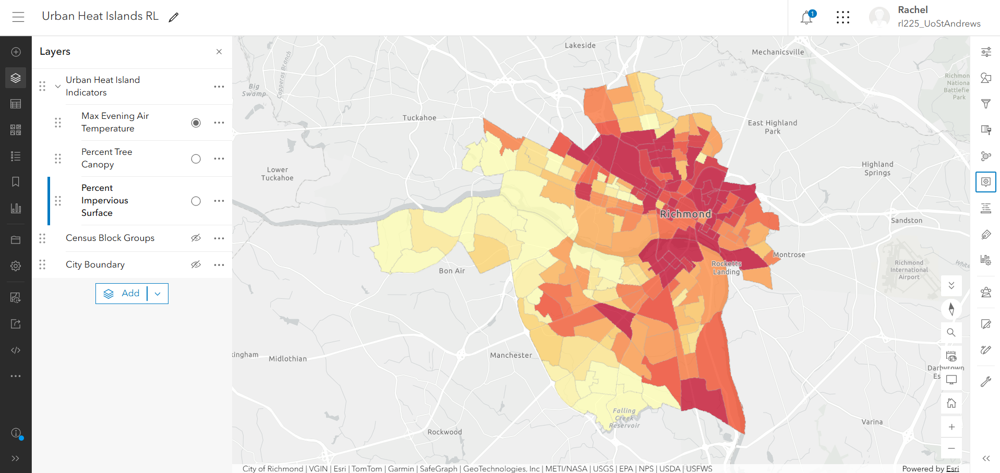

## Challenge 2

### Data

In [ ]:
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns
import geopandas as gpd
import pandas as pd
import plotly.express as px

shapefile_path = 'data/SG_SIMD_2020.shp'
scotland_gdf = gpd.read_file(shapefile_path)

# Set DataZone as the index
scotland_gdf = scotland_gdf.set_index("DataZone")

In [ ]:
# filter for only City of Edinburgh
edinburgh_gdf = scotland_gdf[scotland_gdf["LAName"] == "City of Edinburgh"]

# checking to see if its worked
edinburgh_gdf.head()

In [ ]:
# checking to see if it has a coordinate reference system defined
print(edinburgh_gdf.crs)

In [ ]:
# setting the CRS to EPSG:4326 (WGS 84), to allow me to perform spatial operations and visualizations accurately
edinburgh_gdf = edinburgh_gdf.to_crs('epsg:4326')

In [ ]:
# inspecting the structure of the data and understanding what information is available in the dataset
edinburgh_gdf.columns

### Histograms

**Attribute of Interest: Hospital stays related to alcohol use (standardised ratio)**

More information: https://www.gov.scot/binaries/content/documents/govscot/publications/statistics/2020/09/simd-2020-technical-notes/documents/simd-2020-technical-notes/simd-2020-technical-notes/govscot%3Adocument/SIMD%2B2020%2Btechnical%2Bnotes.pdf

I am using Natural Breaks Map Classification  `mapclassify.NaturalBreaks(y[, k, initial])` and Equal Interval Classification `mapclassify.EqualInterval(y[, k])` to show how although the data is exactly the same for each map, they appear different due to the difference in classification method. To help show this difference I am plotting histograms with breakpoints to show the difference between the classification bins.

In [ ]:
# Number of classes for classification
num_classes = 5

# Using natural breaks  classification
classifier_nb = mc.NaturalBreaks(edinburgh_gdf["HlthAlcSR"], k=num_classes)
print(classifier_nb)
print(min(classifier_nb.bins), max(classifier_nb.bins))
print(classifier_nb.bins) 

# Using equal interval classification
classifier_ei = mc.EqualInterval(edinburgh_gdf["HlthAlcSR" ], k=num_classes)
print(classifier_ei)
print(min(classifier_ei.bins), max(classifier_ei.bins))
print(classifier_ei.bins)

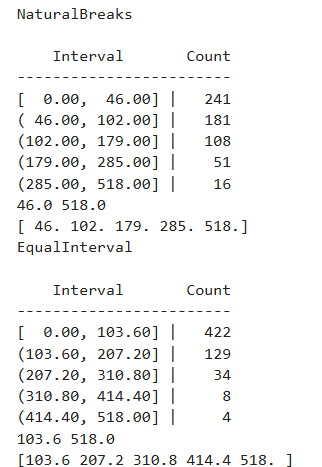

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# one extra property, ax=axes[0], which means it is a matrix of 1 row, two columns.
sns.histplot(data=edinburgh_gdf, x="HlthAlcSR", ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_nb.bins[0], color='red', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb.bins:
    axes[0].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[0].set_title("HlthAlcSR Histogram with Natural Breaks")
axes[0].legend()

# the next plot using now ax=axes[1]
sns.histplot(data=edinburgh_gdf, x="HlthAlcSR", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_ei.bins[0], color='blue', linestyle='dashed', linewidth=2, label='Quantiles')
for bin_value in classifier_ei.bins:
    axes[1].axvline(bin_value, color='blue', linestyle='dashed', linewidth=2)
axes[1].set_title("HlthAlcSR Histogram with Quantiles")
axes[1].legend()

# adjust the plot
plt.tight_layout()
plt.show()

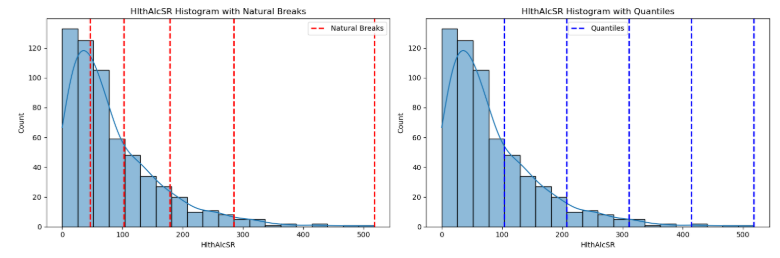

### Static Choropleth Maps

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

edinburgh_gdf.plot(column='HlthAlcSR', ax=axs[0],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_nb.bins}
        )

axs[0].set_title("Choropleth Map with Natural Breaks")

edinburgh_gdf.plot(column='HlthAlcSR', ax=axs[1],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins})

axs[1].set_title("Choropleth Map with Equal Intervals")

plt.tight_layout() #Optional but useful.
plt.show()


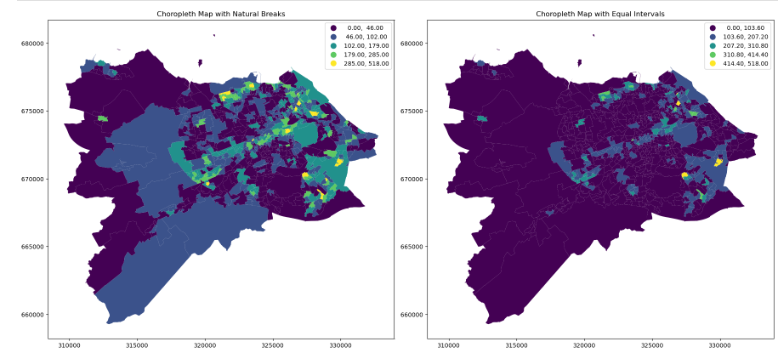

### Interactive Choropleths Maps

**Attribute of interest: Attainment of school leavers (score)**

More information: https://www.gov.scot/binaries/content/documents/govscot/publications/statistics/2020/09/simd-2020-technical-notes/documents/simd-2020-technical-notes/simd-2020-technical-notes/govscot%3Adocument/SIMD%2B2020%2Btechnical%2Bnotes.pdf

In [ ]:
edinburgh_map = edinburgh_gdf.to_crs(epsg=4326)

fig = px.choropleth_map(edinburgh_map,
                        geojson=edinburgh_map,
                           locations=edinburgh_map.index,
                           color="EduAttain",
                           color_continuous_scale="viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.953058, "lon": -3.188165},
                           map_style="carto-positron",
                           zoom=9.5)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

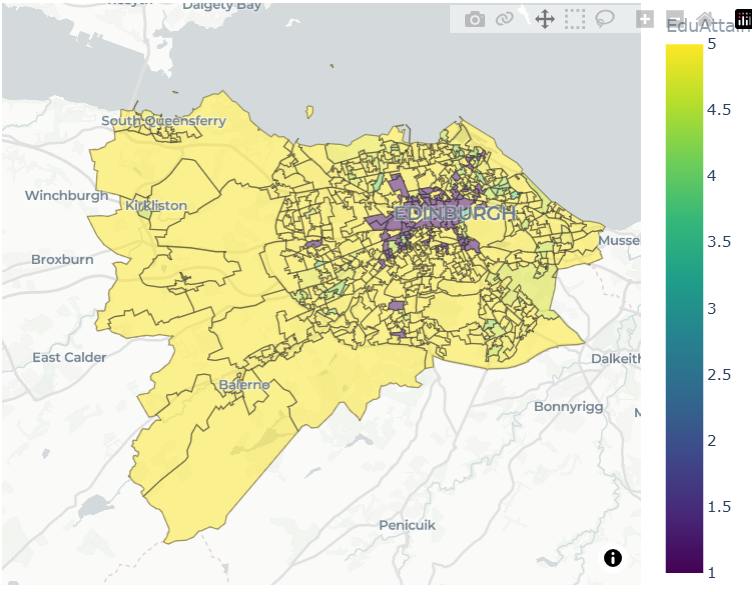

In [ ]:
g_shapefile_path = "data/SIMD_2020_GlasgowCity.shp"
glasgow_gdf = gpd.read_file(g_shapefile_path)

glasgow_gdf.set_index('DataZone', inplace=True)
glasgow_gdf.head()

In [ ]:
num_classes = 5

classifier_nb = mc.NaturalBreaks(glasgow_gdf['EduAttain'], k=num_classes)
glasgow_gdf['classification_nb'] = classifier_nb.yb #yb to get the values from the array.

glasgow_gdf[['EduAttain', 'classification_nb']]

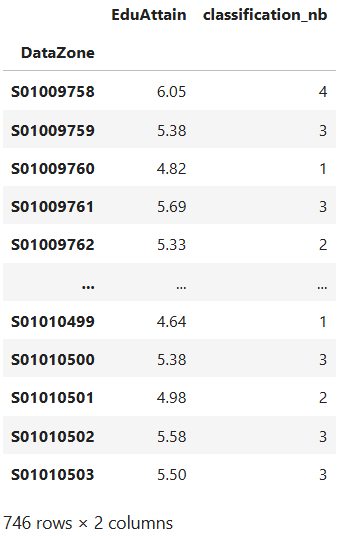

In [ ]:
glasgow_map = glasgow_gdf.to_crs(epsg=4326)

fig_2 = px.choropleth_map(glasgow_map,
                        geojson=glasgow_map,
                           locations=glasgow_map.index,
                           color="EduAttain",
                           color_continuous_scale="viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.866193, "lon": -4.258246},
                           map_style="carto-positron",
                           zoom=9.5)
fig_2.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig_2.show()

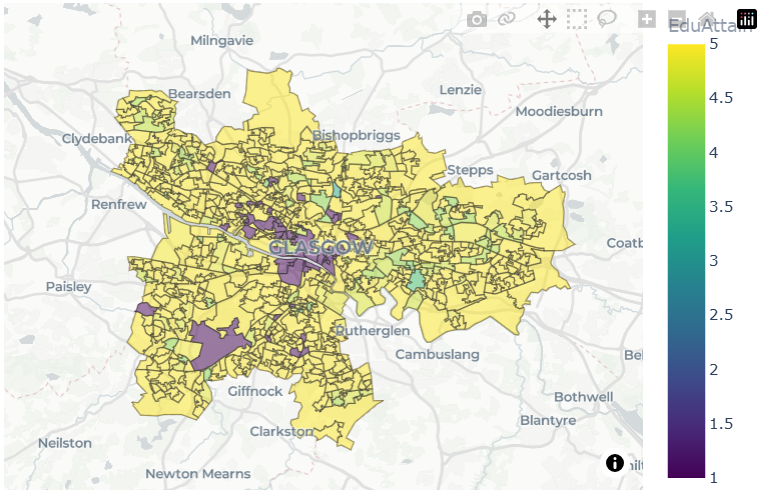

# Lab 5 - Growth and Accessability

In [ ]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

## Challenge 1
Change BBOX to another place (find coordinates at https://bboxfinder.com, choose the format west, south, east, north). Does the pattern repeat?.

In [ ]:
API_KEY = getpass.getpass("Paste your ohsome API key: ")

In [ ]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-4.373245,55.750656,-4.298401,55.791813]          # Newton Mearns, Glasgow

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here with a message if something went wrong
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

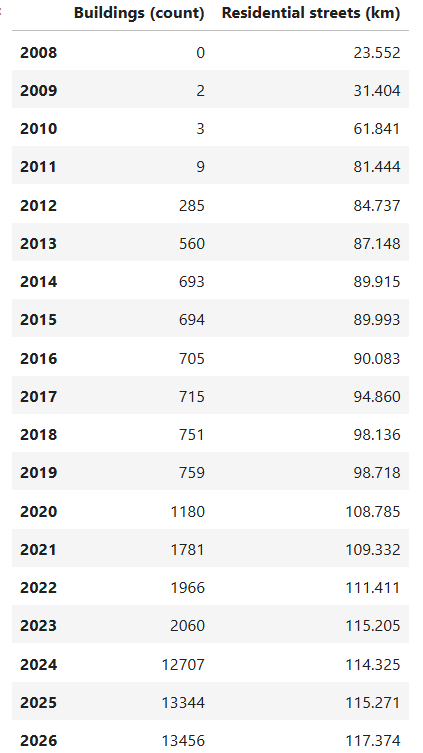

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

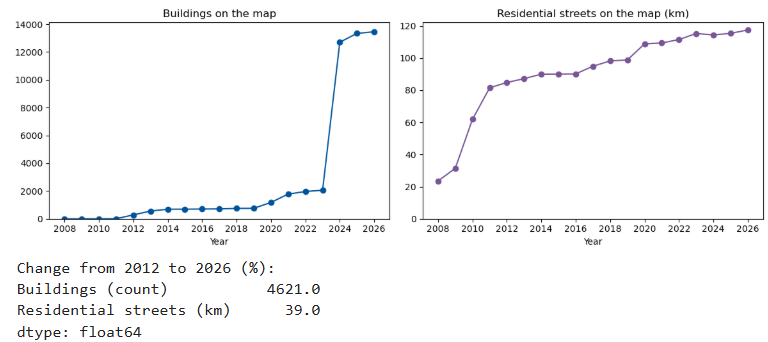

Newton Mearns, Glasgow follows similar pattern to north Edinburgh, while new housing development will have contributed to the increase in buildings, it may also be that not as many people where mapping the buildings in previous years, making the data inaccurate.

Residential streets are easier to identify and map using OpenStreetMap (OSM) than buildings as they require less detailed digitisation. Using residential streets is a better sign of real growth than buildings in a UK city.

## Challenge 2.1

I am measuring the access of pharmacies in Dundee.

In [ ]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

pharmacies = dundee_services[dundee_services["service"] == "Pharmacy"].copy()
print(len(nodes), "street junctions and", len(pharmacies), "Pharmacy")

In [ ]:
pharmacies["node"] = ox.distance.nearest_nodes(G, pharmacies.geometry.x, pharmacies.geometry.y)
pharmacies[["name", "node"]].head()

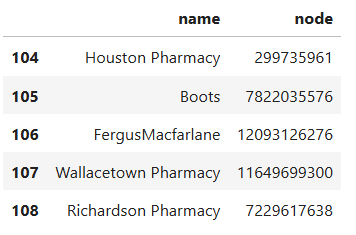

In [ ]:
nearest = nx.multi_source_dijkstra_path_length(G, set(pharmacies["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest pharmacy"})
pharmacies.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest pharmacy (black dots = shops)")
ax.set_axis_off()
plt.show()

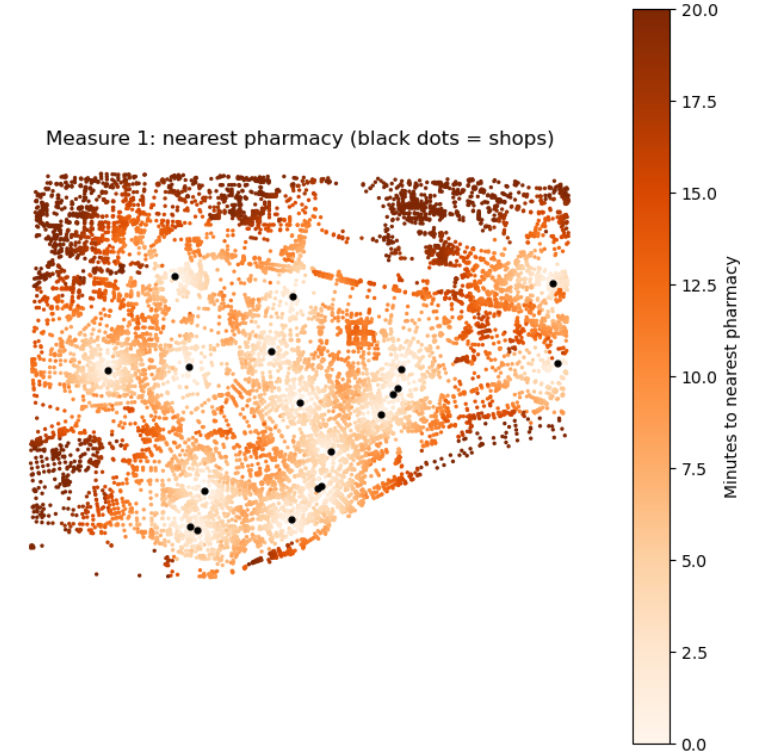

In [ ]:
BETA = 0.069 #beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for pharmacy_node in pharmacies["node"]:
    distances = nx.single_source_dijkstra_path_length(G, pharmacy_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

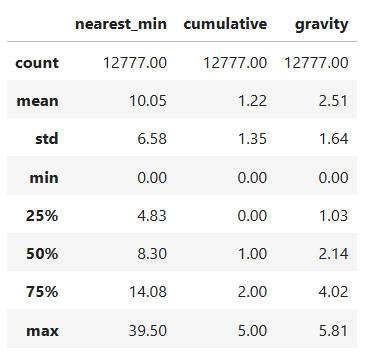

In [ ]:
# here we plot the two measures side by side, using different colour maps and legends.
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: pharmacies within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score (BETA = 0.069)")
for ax in axes:
    ax.set_axis_off()
plt.show()

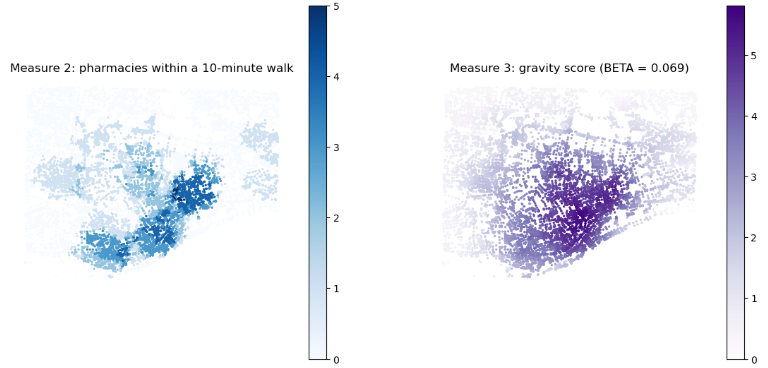

## Challenge 2.2

In [ ]:
BETA = 0.14 

for pharmacy_node in pharmacies["node"]:
    distances = nx.single_source_dijkstra_path_length(G, pharmacy_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

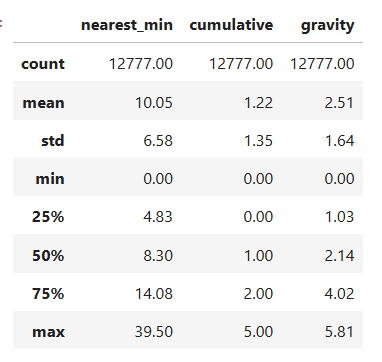

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6.5))

nodes.plot(column="gravity", cmap="Purples", markersize=2, legend=True, ax=ax).set_title("Measure 3: gravity score (BETA = 0.14)")

plt.show()

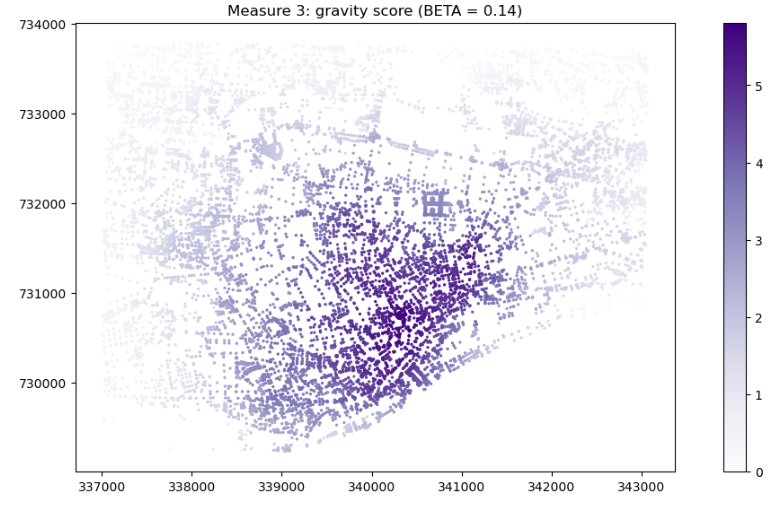

This steeper decay may better represent to who are less mobile such as eldery populations.

## Challenge 3.1

In [ ]:
places = gpd.read_file("data/dundee_overture_places.gpkg").to_crs("EPSG:27700")
print(len(places), "Overture places in Dundee (saved copy)")

In [ ]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
shops = dundee_services[dundee_services["service"] == "Food shop"].copy()

overture_shops_5 = places[is_food & (places["confidence"] >= 0.5)].copy()
overture_shops_8 = places[is_food & (places["confidence"] >= 0.8)].copy()


print("Food shops in OpenStreetMap:      ", len(shops))
print("Food shops in Overture (0.5):     ", len(overture_shops_5))
print("Food shops in Overture (0.8):     ", len(overture_shops_8))

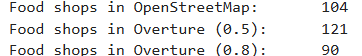

In [ ]:
overture_shops_8["node"] = ox.distance.nearest_nodes(G, overture_shops_8.geometry.x, overture_shops_8.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops_8["node"]), weight="length")
nodes["nearest_min_overture_8"] = pd.Series(nearest_overture) / WALK_SPEED

overture_shops_5["node"] = ox.distance.nearest_nodes(G, overture_shops_5.geometry.x, overture_shops_5.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops_5["node"]), weight="length")
nodes["nearest_min_overture_5"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture (0.5)":      [nodes["nearest_min_overture_5"].median(), (nodes["nearest_min_overture_5"] <= 10).mean() * 100],
    "Overture (0.8)":      [nodes["nearest_min_overture_8"].median(), (nodes["nearest_min_overture_8"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

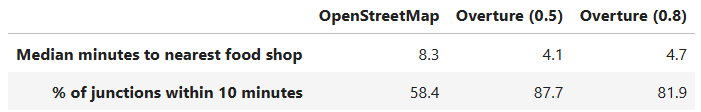

After changing the confidence interval to 0.8, there are now 90 shops (30 less than with 0.5 interval) and the median minutes to the nearest food shop has increased by 0.6 minutes. The percentage of junctions within 10 minutes has decreased by 5.8%.

## Challenge 3.2

In [ ]:
is_pharmacy = places["basic_category"].str.contains("pharmacy|drugstore|chemist", na=False)
overture_pharmacies = places[is_pharmacy & (places["confidence"] >= 0.5)].copy()

print("Pharmacies in OpenStreetMap:", len(pharmacies))
print("Pharmacies in Overture:     ", len(overture_pharmacies))

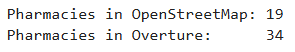

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
pharmacies.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_pharmacies.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacies in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

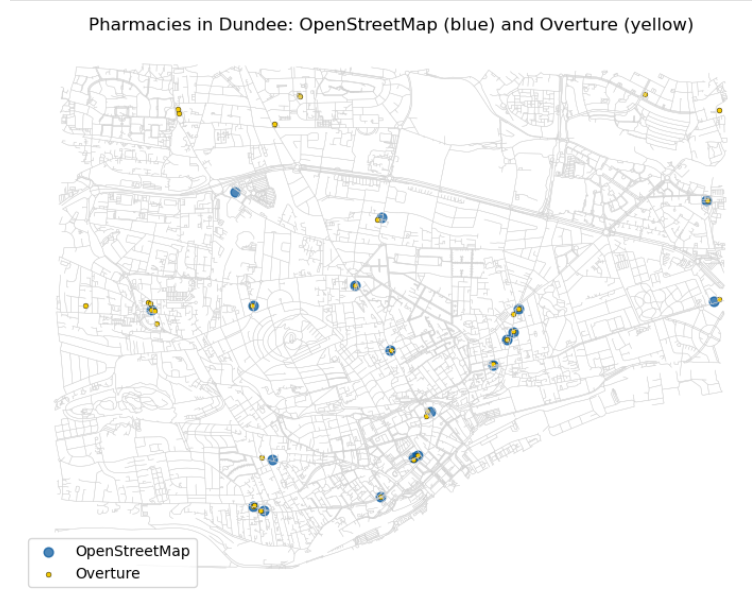

## Challenge 4
Scotland's local living goal is about 10 minutes each way. Change WALK_LIMIT to 800 and run 4.4 and 4.5 again. How many homes still reach all five services?

In [ ]:
PERTH = (56.3960, -3.4370)       # Originally this was Glasgow West End, but to make it easier to find a location, we have moved the study area to Perth.
AREA = 1500                        # metres: the neighbourhood area we study, also to reflect the 15-minute neighbourhood concept 
WALK_LIMIT = 800                  # 10 minutes walking
BIKE_LIMIT = 5000                  # 20 minutes cycling

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [ ]:
G_walk = ox.load_graphml("data/perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

G_bike = ox.load_graphml("data/perth_bike.graphml")
G_bike = ox.project_graph(G_bike, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walk), "junctions | Bike network:", len(G_bike), "junctions")

In [ ]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file("data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes), "residential junctions in the neighbourhood")

In [ ]:
services = gpd.read_file("data/perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bike, homes.geometry.x, homes.geometry.y)   # the same homes on the bike network

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bike, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bike, set(bike_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    homes[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

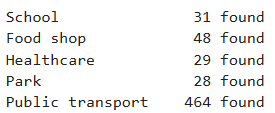

In [ ]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 15-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 20-min cycle"] = [(homes[s + " bike (m)"] <= BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

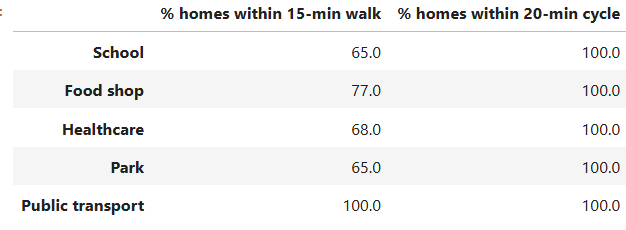

In [ ]:
homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(7, 7), legend_kwds={"label": "Essential services within a 10-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 10-minute neighbourhood?")
ax.set_axis_off()
plt.show()

print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

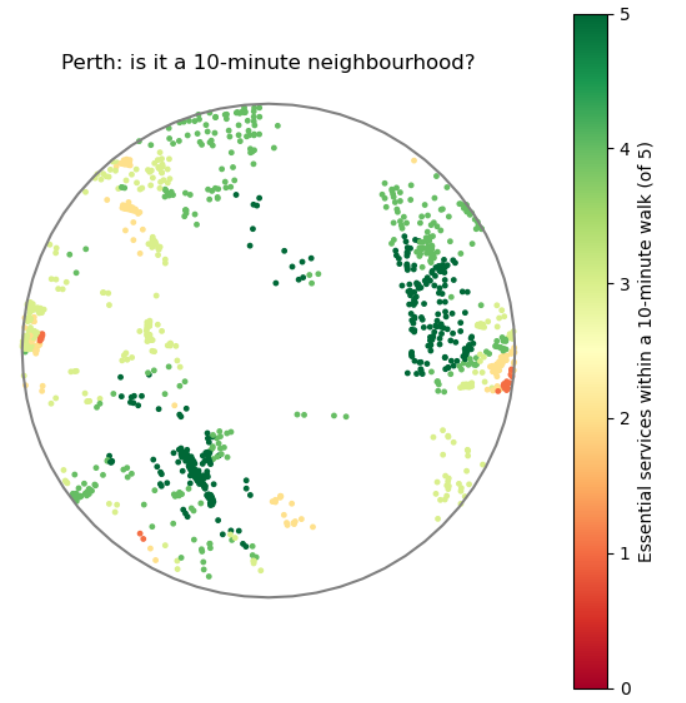

## Challenge 5

In [ ]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [ ]:
food = services[services["service"] == "Food shop"]
food_nodes = set(ox.distance.nearest_nodes(G_walk, food.geometry.x, food.geometry.y))
dist_to_food = nx.multi_source_dijkstra_path_length(G_walk, food_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_food)) & walk_edges["v"].isin(set(dist_to_food))

fig, ax = plt.subplots(figsize=(7, 7))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
food.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of food shop (red); gaps in grey")
ax.set_axis_off()
plt.show()

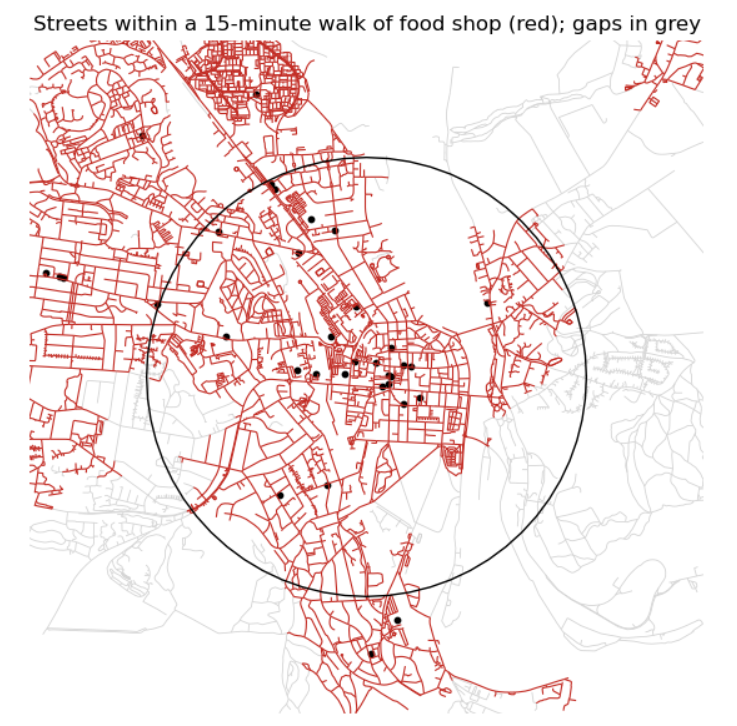

The biggest gaps are on the East side and South West.

## Challenge 6

In [ ]:
CITY = "Dornoch"
CATCHMENT = 1200                        # metres: a 15-minute walk

G_city = ox.load_graphml("data/city_walk_2.graphml")
G_city = ox.project_graph(G_city).to_undirected()        # OSMnx picks the right local projection
crs = G_city.graph["crs"]

parks = gpd.read_file("data/city_parks_2.gpkg").to_crs(crs)
parks["area_m2"] = parks.area

buildings = gpd.read_file("data/city_buildings_2.gpkg").to_crs(crs)
print(len(parks), "parks and", len(buildings), "buildings in", CITY)

In [ ]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
demand.head()

In [ ]:
reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

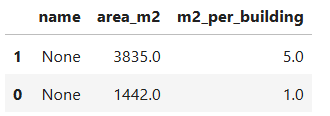

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
homes_city["park_access"].describe().round(0)

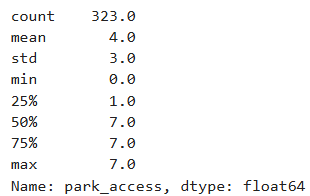

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

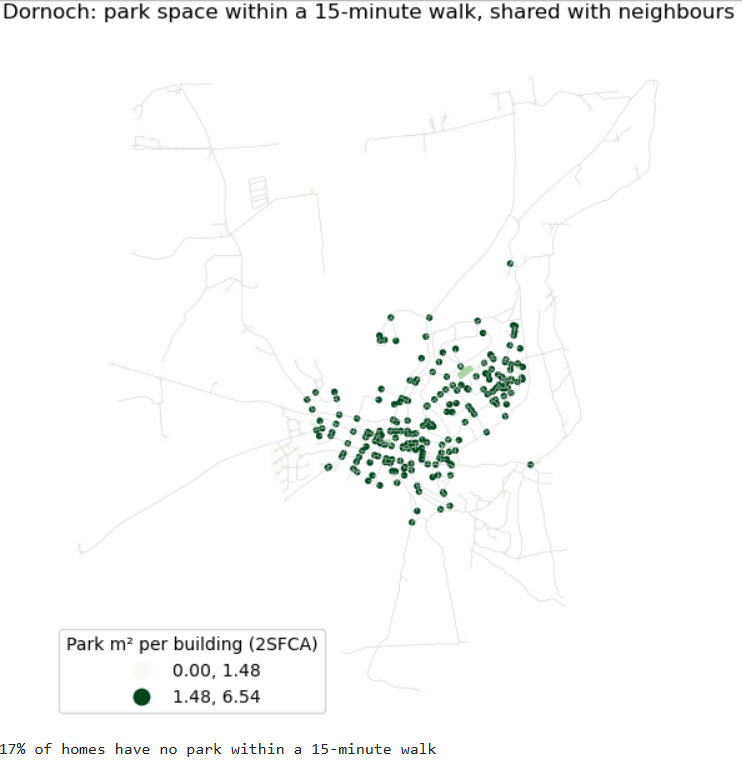

Homes may have a low 2SFCA score despite being close to park as this method of analysis also takes into account the demand of the park. For example a park that is easily accessible by many surrounding buildings would result in a low 2SFCA score  as its available area is shared across a larger number of potential users.

Using buildings as a proxy for demand simplifies the analysis because buildings do not contain the same number of residents. A single block of student accommodation flats could house hundreds of people whereas a detached house many only house 4 - yet these would both count as just one building as be considered to have the same demand.

## Challenge 7
Is De Pijp, Amsterdam a 15-minute neighbourhood? Who has good access to parks and everyday services, and where are the gaps?

In [ ]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 

### Isochrones

In [ ]:
CITY = "De Pijp, Amsterdam"
CENTRE = (52.3540, 4.8930)       

AREA = 1500
DIST = 2000

# 80 metres per minute
WALK_SPEED = 80 

In [ ]:
walk = ox.load_graphml("data/amsterdam_walk.graphml")
walk = ox.project_graph(walk, to_crs="EPSG:28992").to_undirected()

print("Walk network:", len(walk), "junctions")

In [ ]:
buildings = gpd.read_file("data/amsterdam_buildings.gpkg").to_crs("EPSG:28992")

parks = gpd.read_file("data/amsterdam_parks.gpkg").to_crs("EPSG:28992")
parks["area_m2"] = parks.area

print("Buildings in De Pijp:", len(buildings))
print("Parks in De Pijp:", len(parks))

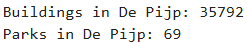

In [ ]:
places = gpd.read_file("data/amsterdam_overture_places.gpkg").to_crs("EPSG:28992")

is_food = places["basic_category"].str.contains("grocery|supermarket|convenience|greengrocer|butcher")
food_shops = places[is_food & (places["confidence"] >= 0.5)].copy()

is_school = places["basic_category"].str.contains("school|education|university|college|preschool|nursery")
schools = places[is_school & (places["confidence"] >= 0.5)].copy()

is_health = places["basic_category"].str.contains("doctor|clinic|pharmacy|hospital|medical|health|drugstore|chemist")
healthcare = places[is_health & (places["confidence"] >= 0.5)].copy()

is_transport = places["basic_category"].str.contains("transport|bus|train|tram|metro|station|rail")
transport = places[is_transport & (places["confidence"] >= 0.5)].copy()

print("Food shops in De Pijp:", len(food_shops))
print("Schools in De Pijp:", len(schools))
print("Healthcare in De Pijp:", len(healthcare))
print("Public transport in De Pijp:", len(transport))

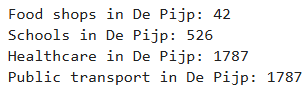

In [ ]:
food_shops["category"] = "Food shops"
schools["category"] = "Schools"
healthcare["category"] = "Healthcare"
transport["category"] = "Public transport"

services = pd.concat([food_shops, schools, healthcare, transport])

services = gpd.GeoDataFrame(services, geometry="geometry", crs="EPSG:28992")

services.head()

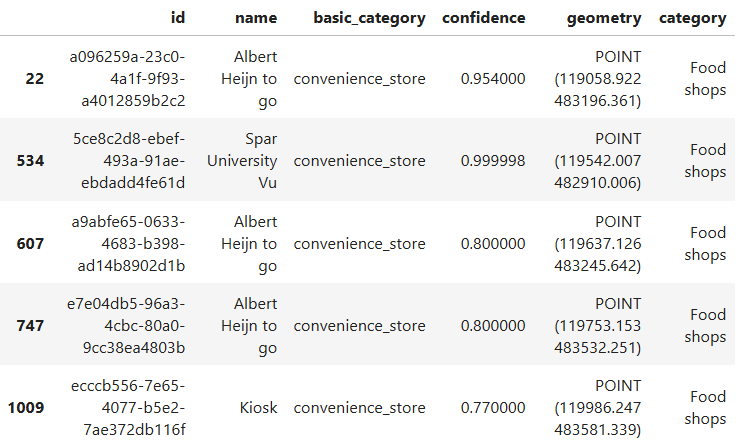

In [ ]:
centre = gpd.GeoSeries.from_xy([CENTRE[1]], [CENTRE[0]], crs="EPSG:4326").to_crs("EPSG:28992")

# the junction nearest the centre
centre_node = ox.distance.nearest_nodes(walk, X=centre.iloc[0].x, Y=centre.iloc[0].y)

distances = nx.single_source_dijkstra_path_length(walk, centre_node, cutoff=AREA, weight="length")

walk_nodes, walk_edges = ox.graph_to_gdfs(walk)

walk_nodes["walk_distance"] = walk_nodes.index.map(distances)

In [ ]:
def isochrone(walk, start_node, metres):
    reachable = nx.ego_graph(walk, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(walk, centre_node, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:28992").plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(walk, centre_node, 15 * WALK_SPEED)
inside = services[services.within(iso15)]
for name, colour in zip(["Food shops", "Schools", "Healthcare", "Public transport"], ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    inside[inside["category"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from the centre of De Pijp, with the services inside")
ax.set_axis_off()
plt.show()

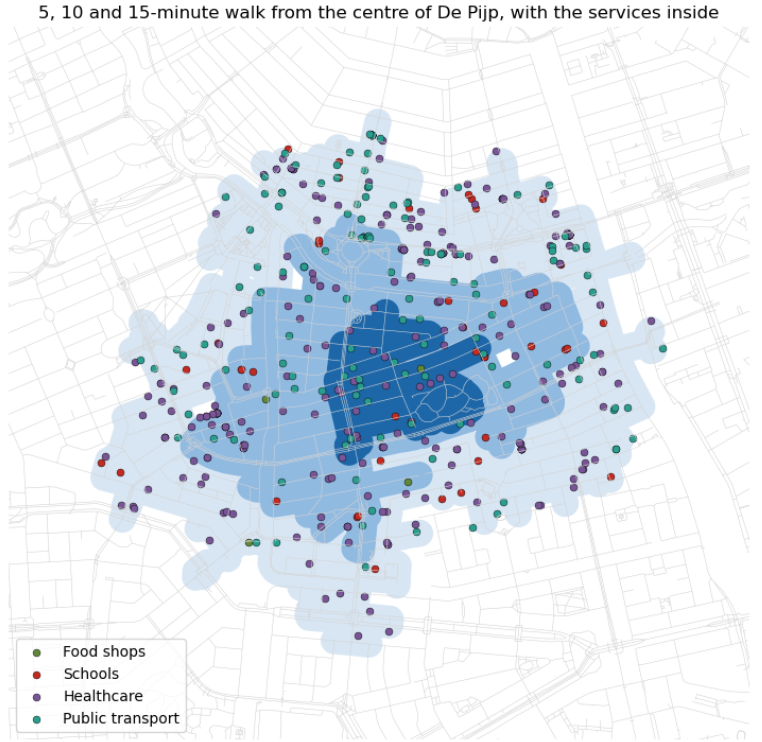

#### Services per isochrone

In [ ]:
# Count of how many services are within 15 minute isochrone
iso15 = isochrone(walk, centre_node, 15 * WALK_SPEED)
inside15 = services[services.within(iso15)]

print(inside15["category"].value_counts())
print(inside15["category"].value_counts().sum(), "services within the 15 minute ischrone")

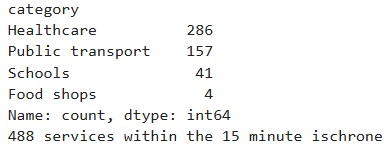

In [ ]:
# Count of how many services are within 10 minute isochrone
iso10 = isochrone(walk, centre_node, 10 * WALK_SPEED)
inside10 = services[services.within(iso10)]

print(inside10["category"].value_counts())
print(inside10["category"].value_counts().sum(), "services within the 10 minute ischrone")

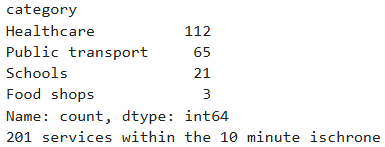

In [ ]:
# Count of how many servicess are within 5 minute isochrone
iso5 = isochrone(walk, centre_node, 5 * WALK_SPEED)
inside5 = services[services.within(iso5)]

print(inside5["category"].value_counts())
print(inside5["category"].value_counts().sum(), "services within the 5 minute ischrone")

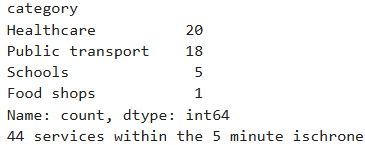

### Two-step floating catchment area (2SFCA)

In [ ]:
parks["node"] = ox.distance.nearest_nodes(walk, parks.representative_point().x, parks.representative_point().y)

centre_800m = centre.buffer(800).iloc[0]

# https://geopandas.org/en/latest/docs/reference/api/geopandas.clip.html
buildings = gpd.clip(buildings, centre_800m)
buildings["node"] = ox.distance.nearest_nodes(walk, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings

demand.head()

In [ ]:
CATCHMENT = 1200

parks["area_m2"] = parks.area

reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(walk, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

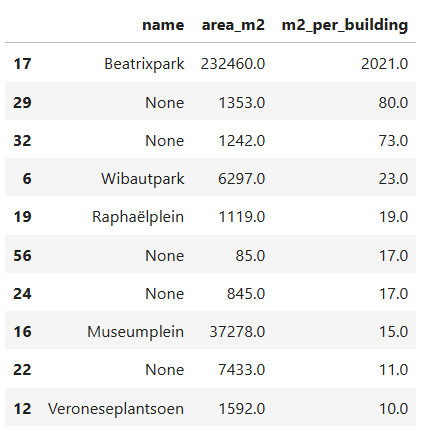

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(walk)
park_access = {node: 0.0 for node in walk.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)] # junctions that have buildings
homes_city["park_access"].describe().round(0)

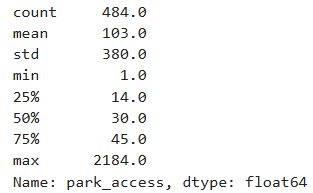

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

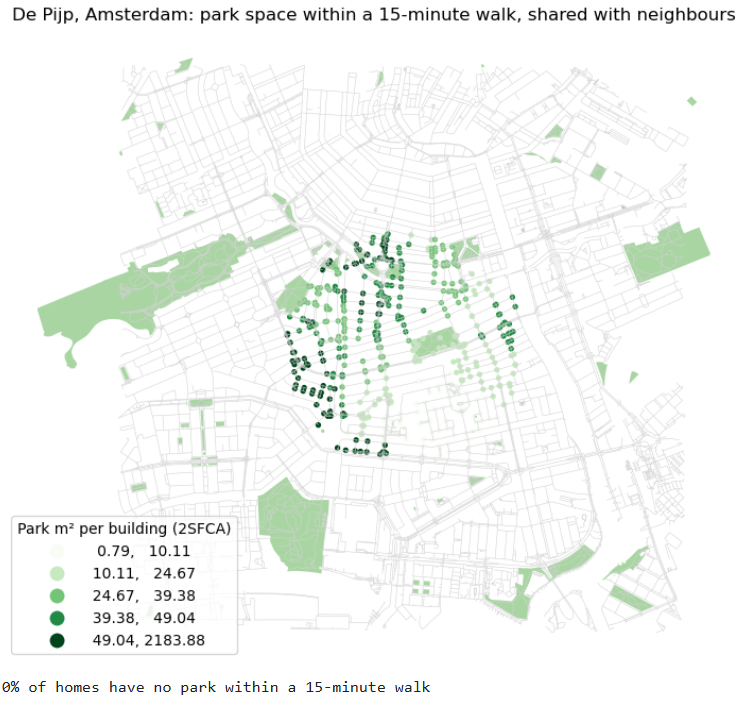

### Summary Table

In [ ]:
median_park_access = homes_city["park_access"].median()
median_park_access

In [ ]:
summary_table = pd.DataFrame({
    "Measure": [
        "Number of parks",
        "Number of homes (buildings) within 800m",
        "Median park m² per building (for homes within 800m of centre)",
        "% of homes with no park within 15 minutes",
        "Services within a 5-minute walk of the centre",
        "Services within a 10-minute walk of the centre",
        "Services within a 15-minute walk of the centre"
    ],
    "Result": [
        len(parks),
        len(homes_city),
        median_park_access.round(2),
        f"{(homes_city['park_access'] == 0).mean():.0%}",
        len(inside5),
        len(inside10),
        len(inside15)]})

summary_table

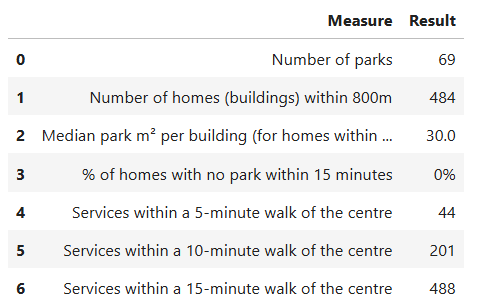

### Conclusion

De Pijp demonstrates strong potential to be considered a 15 minute neighbourhood. 

All 484 buildings within the 800m study area had access to at least one park within 15 minutes, with a median park accessibility score of 30.0 m2 per building. Service availability also increased considerably with walking distance, from 44 services within five minutes to 201 within ten minutes and 488 within fifteen minutes. 

However, provision is uneven across service types: healthcare (286) and public transport (157) dominate, while only 4 food shops were identified. This suggests that proximity to services does not necessarily guarantee access to all everyday needs. 

A key limitation is using buildings rather than population to estimate demand, as residential occupancy varies considerably between buildings (for example a block of flats compared to detached house). This analysis also counts any school, shop or healthcare, which can overestimate how well connected a neighbourhood is because not all services are equally accessible or useful to everyone. It also doesn't indicate that there is or isn't any variety between the types of schools, shops or healthcare services within the area.

# Lab 6 - Geodemographics

## Challenge 1 - Geodemographic Classification

### Main Goal
Geodemographic Classification of Manchester for Local Retail and Service Planning.
The analysis will focus on identifying differences in:
- Household demand, based on age, family composition and household size.
- Economic circumstances, using employment, occupation and qualification levels.
- Housing characteristics, including tenure, overcrowding and dwelling types.
- Accessibility needs, using household car or van availability.

### Topic Selection
For my geodemographic classification of Manchester, I selected eight Census 2021 topics at Output Area (OA) level. The aim is to identify and distinguish neighbourhoods based on the demographic and socio-economic characteristics of their residents, rather than focusing on a single aspect of population composition.
The selected topics are as follows:
- TS007A – Age: to identify differences in population age structure
- TS021 – Ethnic group: to capture ethnic diversity
- TS003 – Household composition: to identify differences in household structures
- TS066 – Economic activity: provides indication of employment patterns and economic contribution
- TS063 – Occupation: helps distinguish different employment profiles
- TS067 – Highest qualification: indication of educational attainment
- TS054 – Tenure: looks at tenure patterns and different kinds of renting
- TS045 – Car or van availability: provides insight into household access to private transport (important when looking at mobility and accessability)


> Identify the variables that will be crucial for effectively segmenting neighbourhoods. Evaluate how this choice may impact the classification results, including a DEA analysis.

### Variable Selection

| Dimension | Selected variables | Importance for classification |
| ----------- | ----------- | -------- |
| Age structure | Aged 15 years and under; Aged 65 years and over | Distinguishes neighbourhoods with younger populations and families from those with older populations. |
| Ethnic composition | White population | Captures differences in ethnic composition across neighbourhoods. |
| Economic position | Population employed; No qualifications; Professional occupations | Highlights differences in employment and socio-economic circumstances. |
| Household composition | Single-person households; Lone-parent households | Distinguishes areas with more single-person households from those with more lone-parent families. |
| Housing and mobility | Private rented; Social rented; No cars or vans in household | Helps identify differences in housing markets and household access to private transport. |

The choice of variables will directly influence the characteristics that K-means identifies when classifying Output Areas. Since the algorithm groups areas according to similarities across the selected variables, the resulting classification will reflect the dimensions given the greatest representation in the dataset.

### Preparing Data

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import seaborn as sns
from scipy.spatial.distance import cdist, pdist
import plotly.express as px
import os

In [ ]:
csv_directory = "data/Manchester"

# We need a list of all CSV files in the folder
csv_files = [file for file in os.listdir(csv_directory) if file.endswith(".csv")]

# An empty DataFrame to store the merged data
merged_data = pd.DataFrame()

# Loop through each CSV file
for csv_file in csv_files:
    csv_path = os.path.join(csv_directory, csv_file) # We create a consistent path
    df_csv = pd.read_csv(csv_path, low_memory=False) #read each file
    # Concatenate/Merge all columns, there is a pitfall here, you will get a duplicate oa_code from all csv files.
    merged_data = pd.concat([merged_data, df_csv], axis=1)

# Save the merged dataset. You might want to do some pre-processing.
merged_data.to_csv("data/merged_manchester_data.csv", index=False)
# Be aware of the mixted dtype you are importing we unfortunatly have to deal with that later.
# eventually you can avoid this to define the dtype on import method.

In [ ]:
#checking data
merged_data.head()

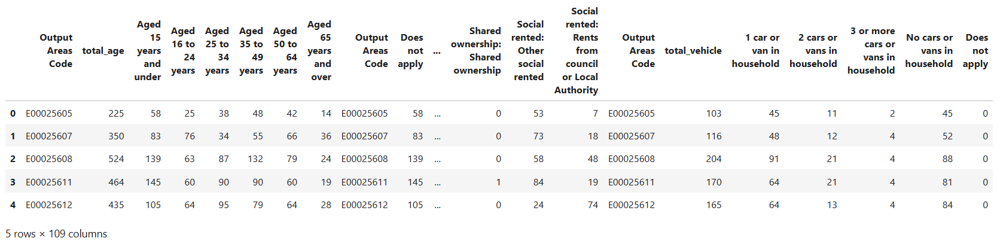

In [ ]:
# Source - https://stackoverflow.com/a/40435354
# Posted by Gene Burinsky, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-09, License - CC BY-SA 4.0

#  getting rid of multiple "Does not apply" columns
merged_data = merged_data.loc[:,~merged_data.columns.duplicated()].copy()

In [ ]:
# taking manchester Output Area codes so I can filter the geodataframe
oa_codes = merged_data["Output Areas Code"].unique()

In [ ]:
shp_path = "data/boundaries/OA_2021_EW_BGC_V2.shp"
gdf = gpd.read_file(shp_path)

gdf.head()

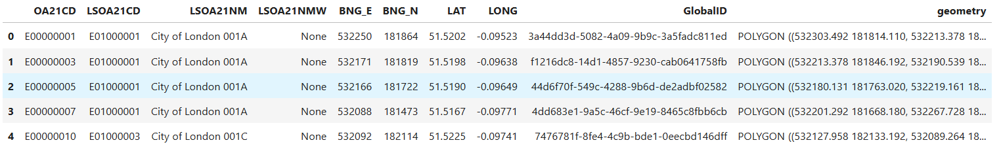

In [ ]:
# Source - https://stackoverflow.com/a/17071908
# Posted by unutbu, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-09, License - CC BY-SA 4.0

# filtering geodataframe to only include mancester output area codes
manchester_gdf = gdf.loc[gdf['OA21CD'].isin(oa_codes)]

manchester_gdf.count()

In [ ]:
csv_path = "data/merged_manchester_data.csv"
csv_data = pd.read_csv(csv_path, low_memory=False)

merged_data = manchester_gdf.merge(csv_data, left_on='OA21CD', right_on='Output Areas Code', how='left')

merged_data.head()

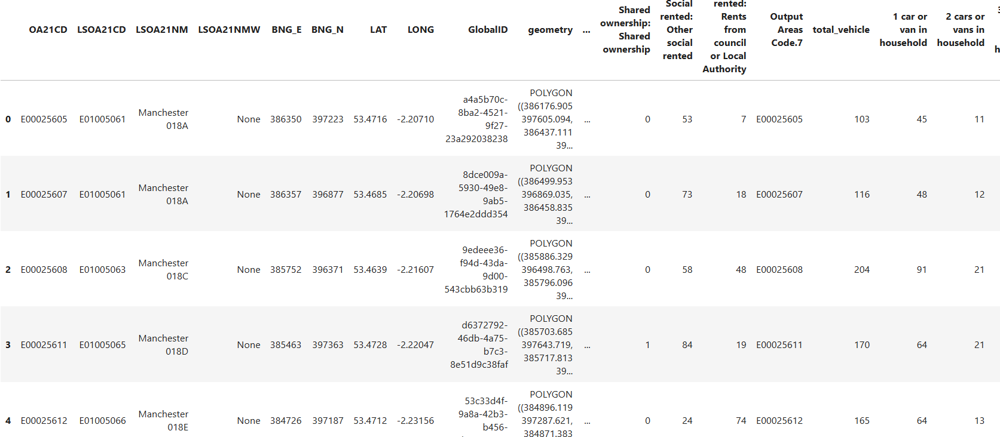

### Descriptive Statistics Analysis

In [ ]:
attributes_to_plot = ['Aged 25 to 34 years',
                      'Economically inactive: Student',
                      'Lives rent free',
                      'No cars or vans in household']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(x=merged_data[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

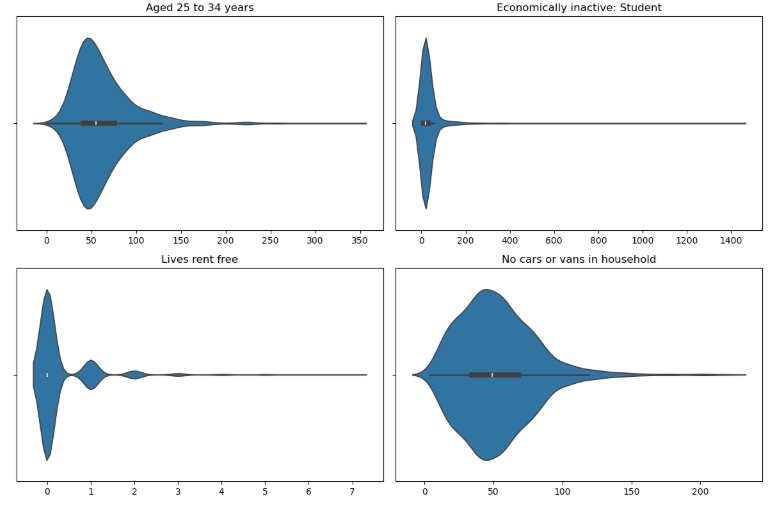

In [ ]:
attributes_to_plot = ['Aged 25 to 34 years',
                      'Economically inactive: Student',
                      'Lives rent free',
                      'No cars or vans in household']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(merged_data[attribute].astype(str), kde=True)
    plt.title(attribute)

plt.tight_layout()
plt.show()

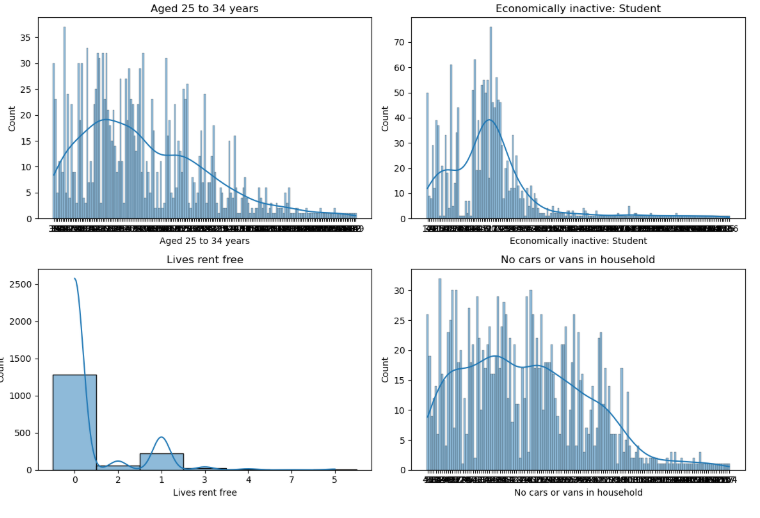

### Standardisation

In [ ]:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
        # The data have several empty values, so you need to process them, forcing them to be a numeric or NaN value
        value = pd.to_numeric(dataframe[value_col], errors='coerce')
        total = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

In [ ]:
# creating totals for selected variables

# total population employed
merged_data["population_employed"] = (
    merged_data['Economically active (excluding full-time students): In employment: Employee: Full-time'] +
    merged_data['Economically active (excluding full-time students): In employment: Employee: Part-time'] +
    merged_data['Economically active (excluding full-time students): In employment: Self-employed with employees: Full-time']+
    merged_data['Economically active (excluding full-time students): In employment: Self-employed with employees: Part-time']+
    merged_data['Economically active (excluding full-time students): In employment: Self-employed without employees: Full-time']+
    merged_data['Economically active (excluding full-time students): In employment: Self-employed without employees: Part-time']+
    merged_data['Economically active (excluding full-time students): Unemployed: Seeking work or waiting to start a job already obtained: Available to start working within 2 weeks']+
    merged_data['Economically active and a full-time student: In employment: Employee: Full-time']+
    merged_data['Economically active and a full-time student: In employment: Employee: Part-time']+
    merged_data['Economically active and a full-time student: In employment: Self-employed with employees: Full-time']+
    merged_data['Economically active and a full-time student: In employment: Self-employed with employees: Part-time']+
    merged_data['Economically active and a full-time student: In employment: Self-employed without employees: Full-time']+
    merged_data['Economically active and a full-time student: In employment: Self-employed without employees: Part-time'])

# single person households
merged_data["single_person_households"] = (
    merged_data["One-person household: Aged 66 years and over"] +
    merged_data["One-person household: Other"])

# lone-parent households
merged_data["lone_parent_households"] = (
    merged_data["Single family household: Lone parent family: All children non-dependent"] +
    merged_data["Single family household: Lone parent family: With dependent children"]
)

# private rented
merged_data["private_rented"] = (
    merged_data["Private rented: Other private rented"] +
    merged_data["Private rented: Private landlord or letting agency"])

# social rented
merged_data["social_rented"] = (
    merged_data["Social rented: Other social rented"] +
    merged_data["Social rented: Rents from council or Local Authority"])

# white population
merged_data["white_population"] = (
    merged_data["White: English, Welsh, Scottish, Northern Irish or British"] +
    merged_data["White: Gypsy or Irish Traveller"] +
    merged_data["White: Irish"] +
    merged_data["White: Other White"] +
    merged_data["White: Roma"])

In [ ]:
total_cols = [
    "total_age",
    "total_age",
    "total_ethnicity",
    "total_economic",
    "total_qualifications",
    "total_occupations",
    "total_households",
    "total_households",
    "total_tenure",
    "total_tenure",
    "total_vehicle"]

value_cols = [
    "Aged 15 years and under",
    "Aged 65 years and over",
    "white_population",
    "population_employed",
    "No qualifications",
    "2. Professional occupations",
    "single_person_households",
    "lone_parent_households",
    "private_rented",
    "social_rented",
    "No cars or vans in household"]

In [ ]:
result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

# Concatenate the resulting tables.
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)
concatenated_df.head()

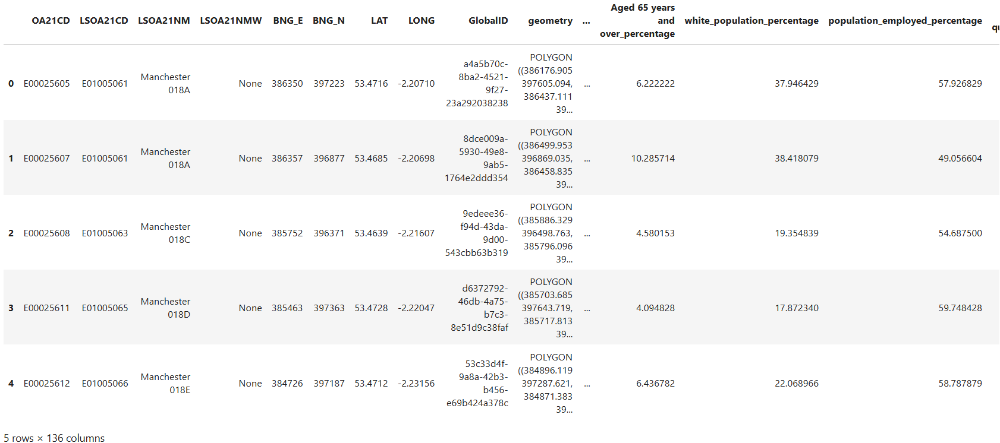

In [ ]:
# Subsetting the attributes we need, we dont need the total for now.
keep_cols= [
    "OA21CD",
    "LSOA21CD",
    "geometry",
    'population_employed',
    'white_population',
    'population_employed',
    'single_person_households',
    'lone_parent_households',
    'private_rented',
    'social_rented',
    'Aged 15 years and under_percentage',
    'Aged 65 years and over_percentage',
    'white_population_percentage',
    'population_employed_percentage',
    'No qualifications_percentage',
    '2. Professional occupations_percentage',
    'single_person_households_percentage',
    'lone_parent_households_percentage',
    'private_rented_percentage',
    'social_rented_percentage',
    'No cars or vans in household_percentage']
 
manchester_census_data = concatenated_df[keep_cols]

In [ ]:
# Calculate z-score for each column, but we need to initially filter only the float attributes.
# bcs you can't calculate that for the OA code

numeric_columns = manchester_census_data.select_dtypes(include='float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
z_score_df.head()

### Adjusting for multicollinearity

In [ ]:
corr = z_score_df.corr()
corr.style.background_gradient(cmap='coolwarm')

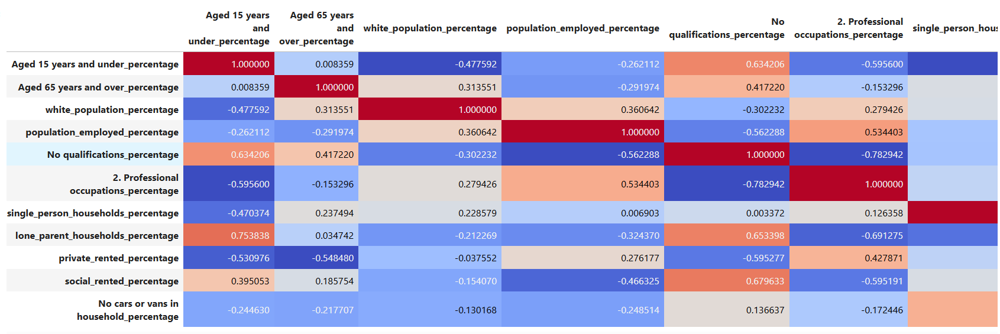

In [ ]:
plt.matshow(z_score_df.corr())
plt.show()

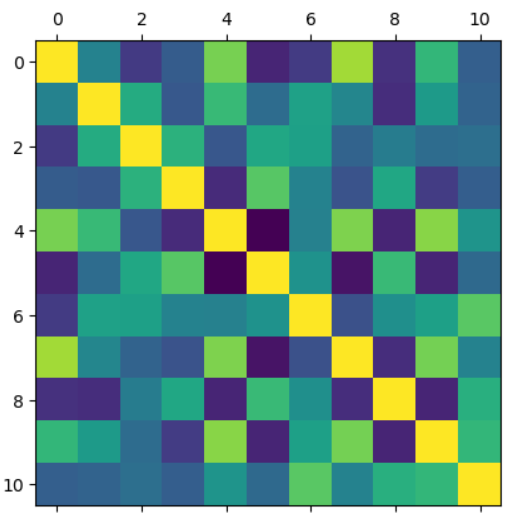

In [ ]:
threshold = 0.7 # We can adapt this based on waht we have in our data. Recall the subjetivity issue?
# So if we include .8 then we wont be able to reduce any variables., so I took the threshold to 70%

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()

# The plot will represent  BINARY table 0 for false( out of the threshold) and 1 for above the threshold.

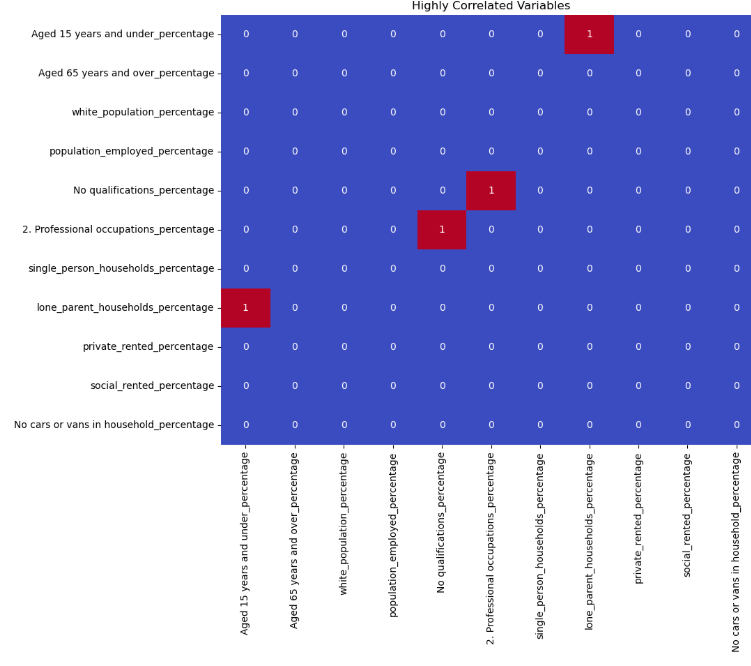

In [ ]:
z_score_df.drop(['lone_parent_households_percentage', 'No qualifications_percentage'], axis=1, inplace=True)
z_score_df.info()

In [ ]:
corr_2 = z_score_df.corr()
corr_2.style.background_gradient(cmap='coolwarm')

In [ ]:
threshold = 0.7
highly_correlated_2 = (corr_2.abs() > threshold) & (corr_2.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated_2, cmap='coolwarm', cbar=False, annot=True)

plt.title('New Highly Correlated Variables')
plt.show()

In [ ]:
contains_nan = z_score_df.isna().any().any()

if contains_nan:
    print("The DataFrame contains NaN values.")
else:
    print("The dataFrame does not contain NaN values.")

In [ ]:
z_score_df.fillna(z_score_df.mean(), inplace=True)
z_score_df.head()

### K-means clustering 

In [ ]:
# KMeans with 10 clusters
kmeans = KMeans(n_clusters=10)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_

z_score_df.head()

In [ ]:
plt.hist(labels)

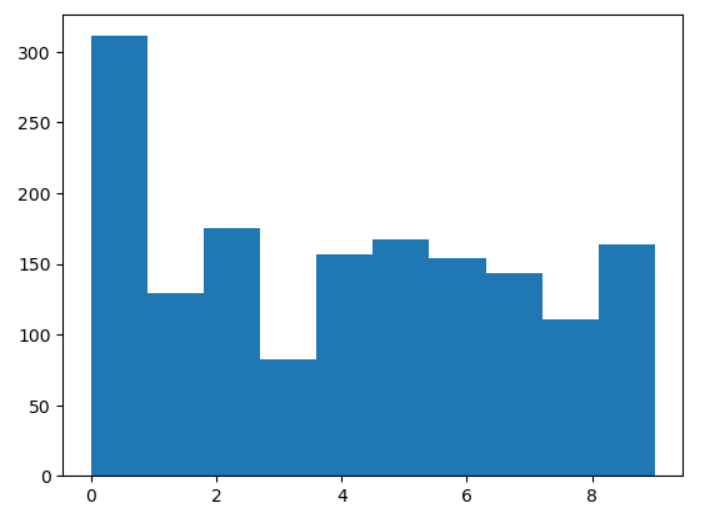

In [ ]:
Sum_of_squared_distances = []

K_range = range(1,15)

for k in K_range:
 km = KMeans(n_clusters=k)
 km = km.fit(z_score_df)
 Sum_of_squared_distances.append(km.inertia_)
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

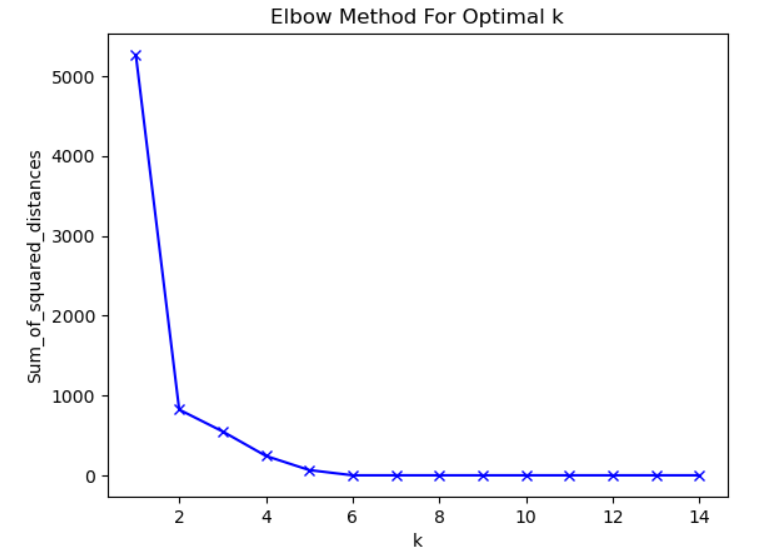

In [ ]:
import numpy as np
def elbow(dataframe, n):
    kMeansVar = [KMeans(n_clusters=k).fit(dataframe.values) for k in range(1, n)] #making use of list comprehensions.
    centroids = [X.cluster_centers_ for X in kMeansVar]
    k_euclid = [cdist(dataframe.values, cent) for cent in centroids]
    dist = [np.min(ke, axis=1) for ke in k_euclid]
    wcss = [sum(d**2) for d in dist]
    tss = sum(pdist(dataframe.values)**2)/dataframe.values.shape[0]
    bss = tss - wcss
    plt.plot(bss)
    plt.show()
 
elbow(z_score_df,15)

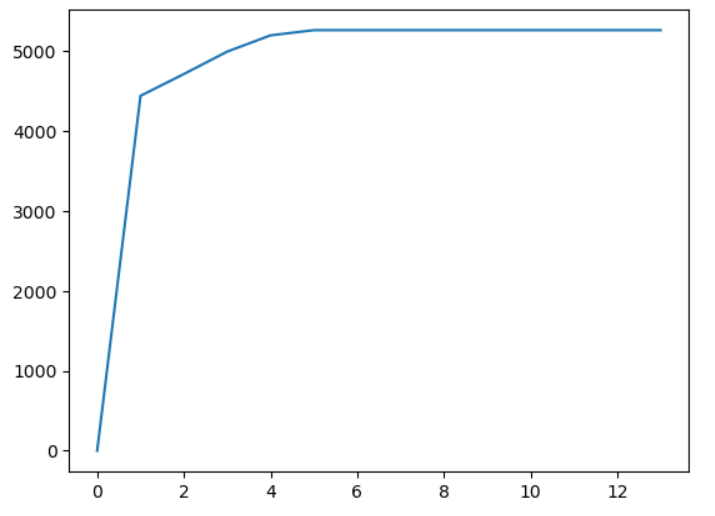

### Optimum number of clusters 
I have chose to carry out KMeans clustering method with 6 clusters, after the validation with the Elbow method.

In [ ]:
kmeans = KMeans(n_clusters=6)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_

z_score_df['Cluster'] = kmeans.labels_

In [ ]:
print(z_score_df.columns)

In [ ]:
# Code based on the example provided here: 
# https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html#sphx-glr-auto-examples-decomposition-plot-pca-iris-py

plt.figure(figsize=(12, 8))

kmeans = KMeans(n_clusters=6)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA analysys.
pca = PCA(n_components=2).fit(stand_data_scaled) #PCA with 2 components, we can also use 3 components, but for now we will use 2 to make it easier to visualize the clusters.
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

# Create a scatter plot
fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")


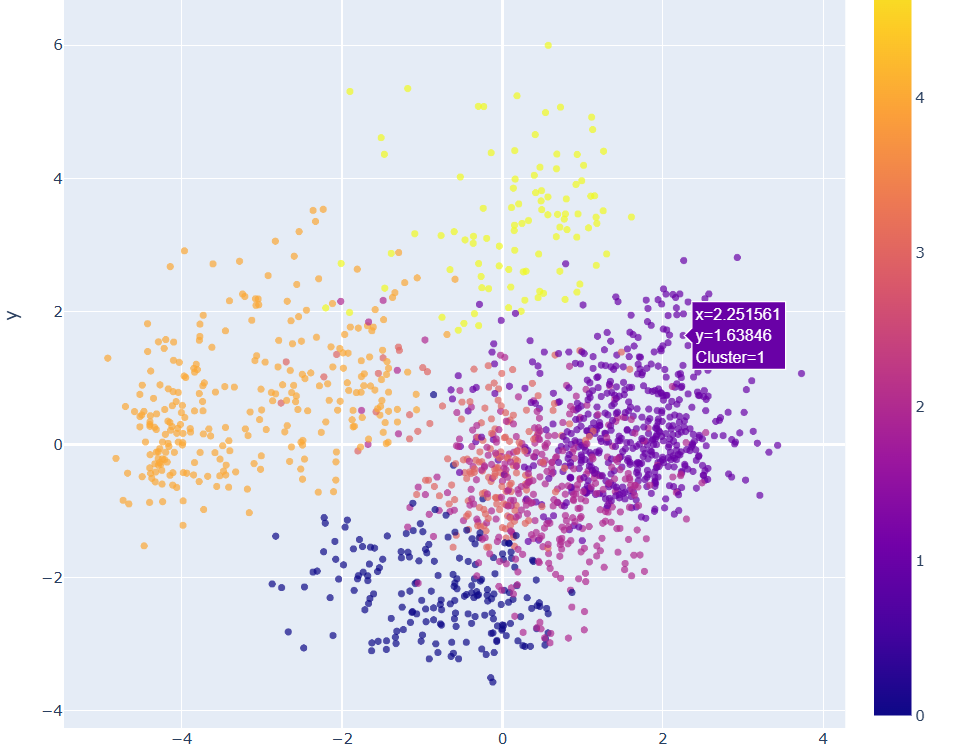

In [ ]:
# Here is a static figure with the point variability included in the x/y-axis label.
# So we can see what variability is provided by each component.

kmeans = KMeans(n_clusters=6)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

# Standardize the data for PCA
scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA
pca = PCA(n_components=2).fit(stand_data_scaled)
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=clusters, palette='viridis', s=50, alpha=0.7)
plt.title('Cluster Plot against 1st 2 Principal Components')
plt.xlabel(f'Principal Component 1 variation: {variance_ratio[0]*100:.2f}%')
plt.ylabel(f'Principal Component 2 variation: {variance_ratio[1]*100:.2f}%')
plt.legend(title='Clusters')
plt.show()


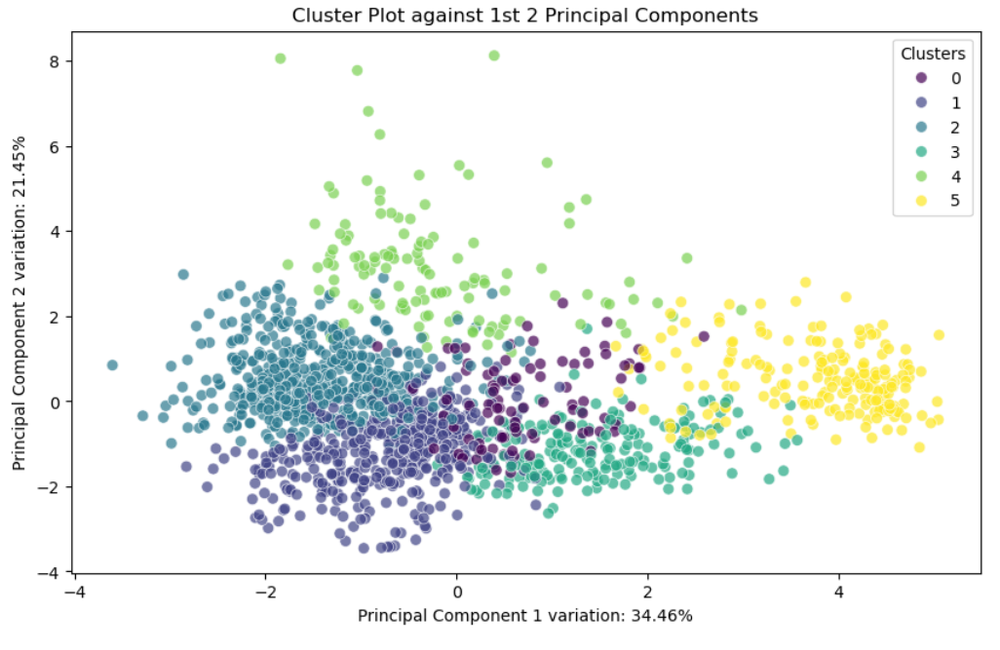

### Evaluating cluster groups (PCA)
The following radar charts help interpret the cluster centres, but they do not show how well the clusters are separated geographically in data space.

In [ ]:
# KMeans clustering
kmeans = KMeans(n_clusters=6)
clusters = kmeans.fit_predict(z_score_df)
cluster_centers = kmeans.cluster_centers_


# Get the cluster centers
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=z_score_df.columns)

# Create a new DataFrame with cluster assignments and column names
#result_df = pd.DataFrame({'Cluster': clusters, 'Column': z_score_df.columns})

cluster_centers.head(6)

#### Cluster 2
- very high proportion of children
- above-average social renting
- more households without a car
- lower professional occupations
- less white population

In [ ]:
# Code adapted from:
# https://matplotlib.org/stable/gallery/pie_and_polar_charts/polar_demo.html

first_row_centers = cluster_centers.iloc[0, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

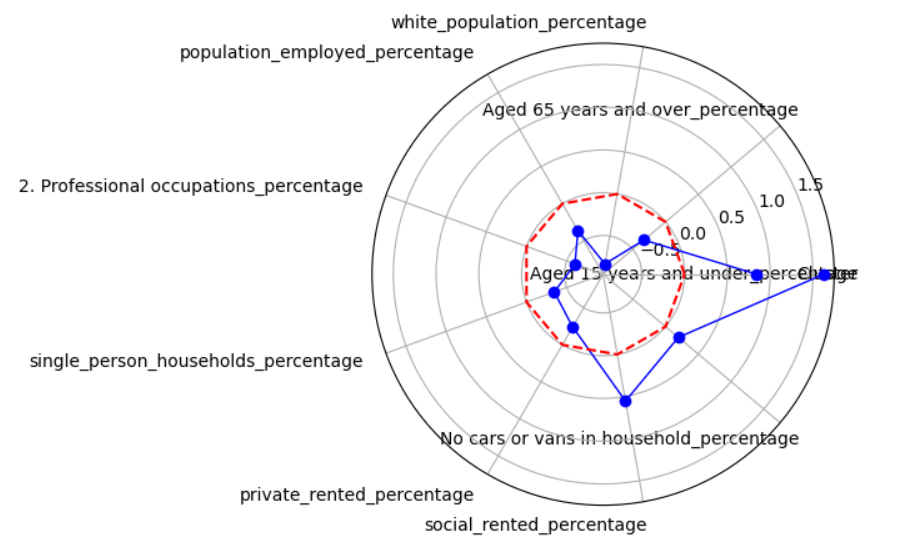

#### Cluster 5
- very high proportion of children
- above-average employment
- above-average professional occupations
- lower social renting
- lower car deprivation

In [ ]:
third_row_centers = cluster_centers.iloc[1, :]

num_features = len(third_row_centers)

theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, third_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(third_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()

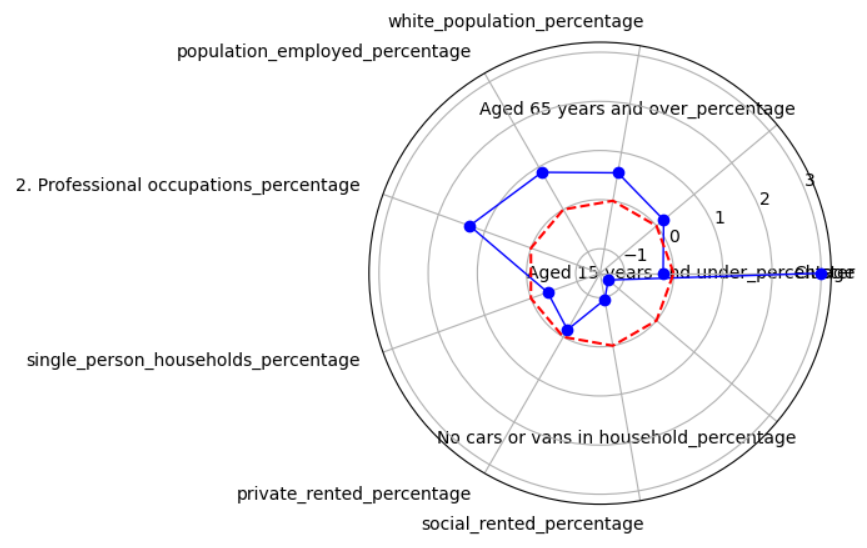

#### Cluster 3
- very high proportion of children
- above-average employment
- above-average professional occupations
- lower social renting
- lower car deprivation

In [ ]:
third_row_centers = cluster_centers.iloc[2, :]

num_features = len(third_row_centers)

theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, third_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(third_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()

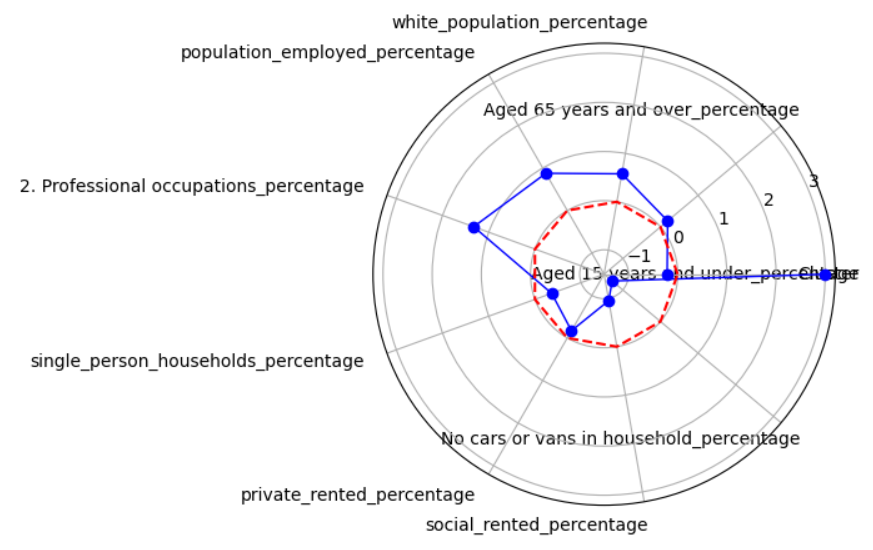

#### Cluster 4
- high proportions of children
- high proportions of older residents
- more single-person households
- more social renting
- more households without a car

In [ ]:
fourth_row_centers = cluster_centers.iloc[3, :]

num_features = len(fourth_row_centers)

theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, fourth_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(fourth_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()

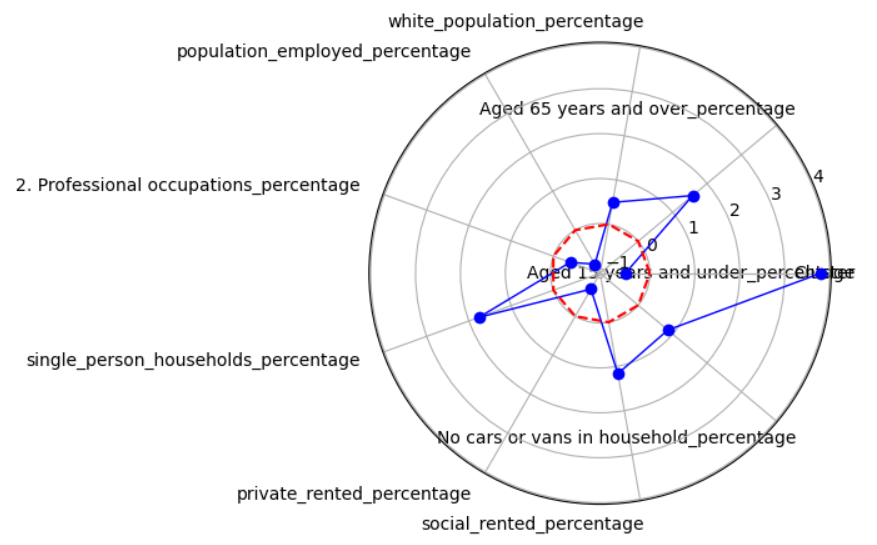

#### Cluster 0
- very high private renting
- high levels of households without a car
- above-average professional occupations
- lower social renting

In [ ]:
fifth_row_centers = cluster_centers.iloc[4, :]

num_features = len(fifth_row_centers)

theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, fifth_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(fifth_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()

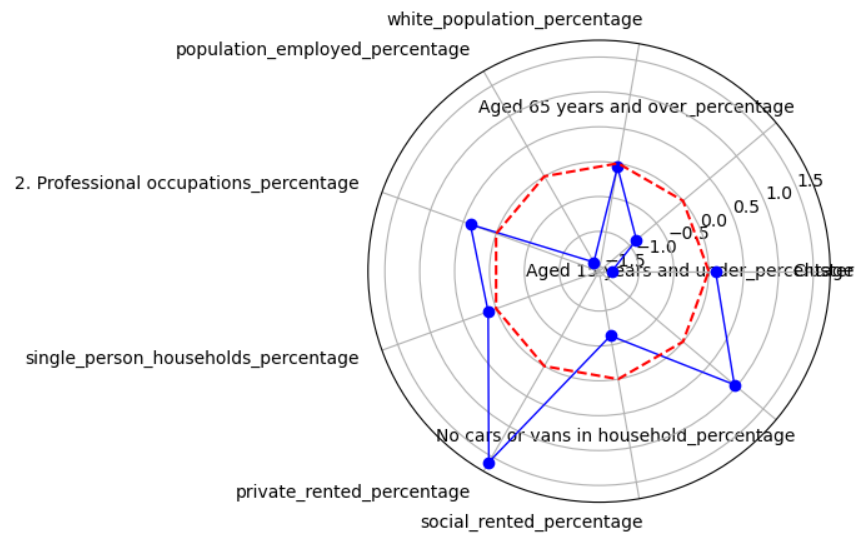

#### Cluster 1
- higher proportions of elderly residents
- above-average White population
- fewer children
- lower professional occupations
- lower rental housing

In [ ]:
sixth_row_centers = cluster_centers.iloc[5, :]

num_features = len(sixth_row_centers)

theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, sixth_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
ax.plot(theta, np.zeros_like(sixth_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()

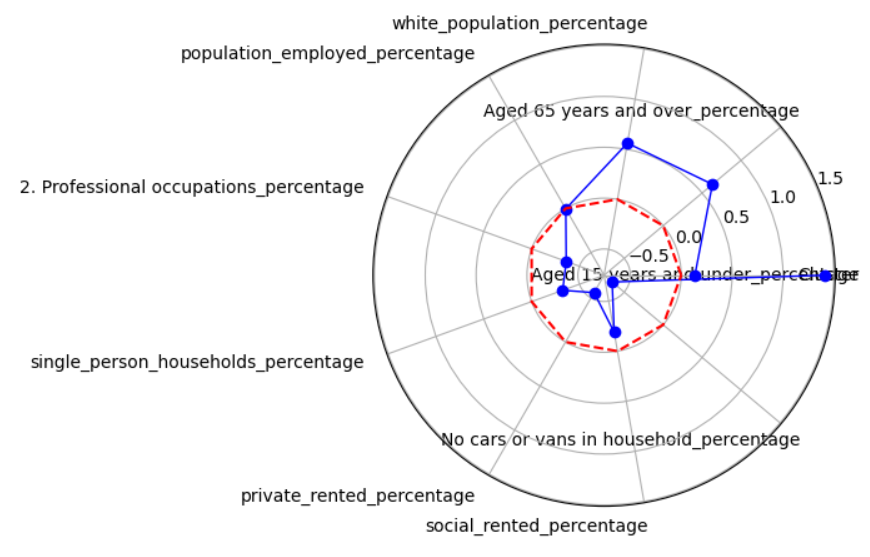

In [ ]:
list(z_score_df.columns)

In [ ]:
z_score_df.drop([
 'Aged 15 years and under_percentage',
 'Aged 65 years and over_percentage',
 'white_population_percentage',
 'population_employed_percentage',
 '2. Professional occupations_percentage',
 'single_person_households_percentage',
 'private_rented_percentage',
 'social_rented_percentage',
 'No cars or vans in household_percentage'], axis=1, inplace=True)

z_score_df.info()

In [ ]:
final_df = pd.concat([manchester_census_data, z_score_df], axis=1, ignore_index=False)
final_df.head()

### Mapping Clusters

In [ ]:
# Source - https://stackoverflow.com/a/40435354
# Posted by Gene Burinsky, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-09, License - CC BY-SA 4.0

final_df = final_df.loc[:, ~final_df.columns.duplicated()]

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='OpenStreetMap')

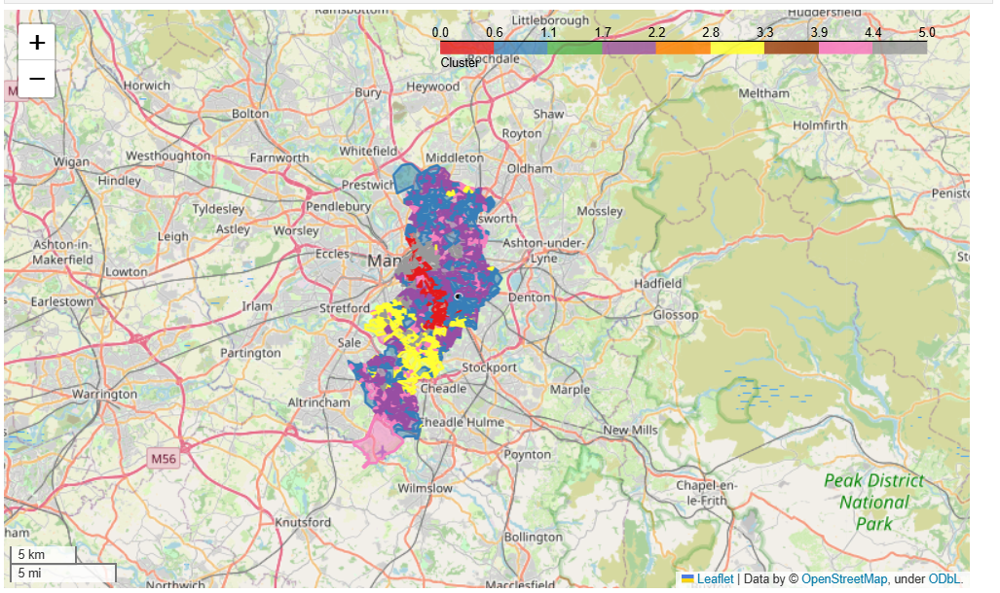

### Naming Cluster Groups

In [ ]:
def rename_column(x): 
    x = str(x)
    x = x.replace("0", "Privately rented, urban neighbourhoods")
    x = x.replace("1", "Older White Neighbourhoods")
    x = x.replace("2", "Younger Socially Rented Neighbourhoods")
    x = x.replace("3", "Younger Professional Neighbourhoods")
    x = x.replace("4", "Mixed-Age Social Housing Neighbourhoods")
    x = x.replace("5", "Affluent Family Neighbourhoods")
    # Add more values as you need. As many as clusters you have
    return x
        
final_df['Cluster'] = final_df['Cluster'].apply(rename_column)

### Final Map

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='OpenStreetMap')

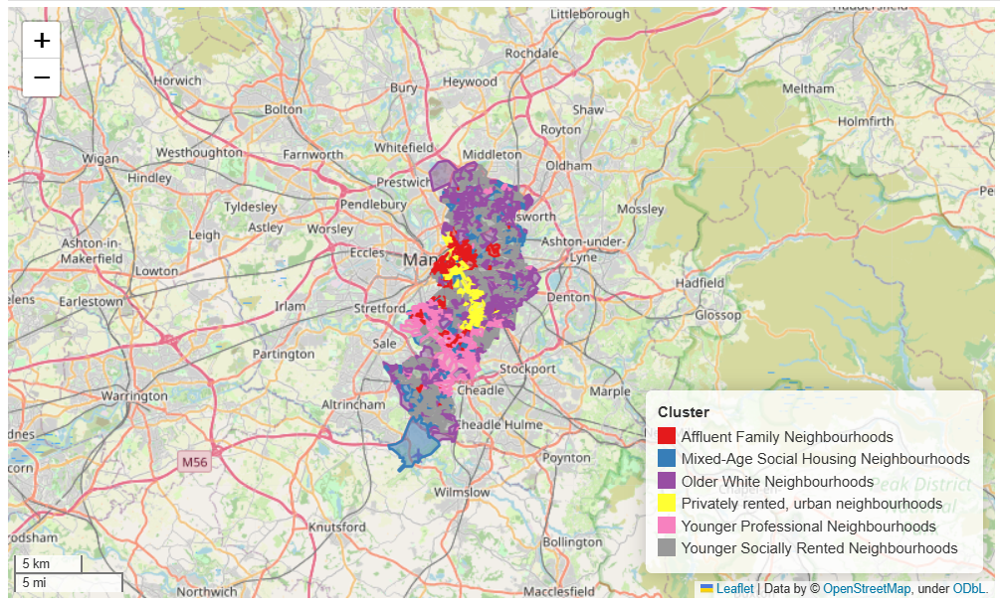

### Conclusion

#### Subjectivity and analytical decisions
Geodemographic classification is subjective, as the neighbourhood groups depend on the variables selected, the number of clusters specified and the analytical methods used. There is no single correct classification of Manchester, as different combinations of census variables could produce alternative representations of its demographic and socio-economic characteristics. 

In constructing this classification, I selected variables covering five broad dimensions: age structure, ethnic composition, economic position, household composition, and housing and transport. These were chosen to capture different aspects of neighbourhood characteristics rather than relying on a single measure. Standardising the variables was important because they were measured on different scales, ensuring that variables with larger numerical values did not disproportionately influence the clustering process.

I also took into consideration the potential for overlap between variables and the extent to which each contributed meaningful information. Examining correlations and evaluating the resulting cluster profiles were important steps in assessing the suitability of the variable selection.

#### Challenges and insights
One of the main challenges was selecting variables that represented the diversity of Manchester without introducing duplication. The selection process required consideration of which characteristics were most relevant to distinguishing neighbourhoods.

The classification demonstrated that neighbourhoods can share  demographic characteristics while differing considerably in others. For example, some clusters contained high proportions of younger residents but differed in employment, housing tenure and access to private transport. This demonstrates the value of a multidimensional approach, neighbourhoods cannot be understood trhough only one aspect.

I noticed that clusters 3 and 5 both contained relatively high proportions of younger residents, higher employment and professional occupation scores, and lower levels of social renting. This raised questions about whether the two groups represented sufficiently distinct neighbourhood types. 

#### Potential applications
One potential application is public health planning. Clusters characterised by higher levels of social renting, lower employment and limited access to private transport could help identify neighbourhoods where barriers to accessing healthcare and other services may be more pronounced. This could inform the geographical targeting of health promotion initiatives, community health services and preventative interventions.

However, the classification has limitations. It is based on aggregate Census data and describes neighbourhood-level characteristics rather than individuals. It should not be assumed that every resident within a cluster shares the same characteristics or lived experience. Furthermore, Census data provides a snapshot of population characteristics at a particular point in time, meaning neighbourhood profiles may change.